# Jiaxin: Parts F, G and H
## Hyperparameter tuning, ensembles, final evaluation and recommendation

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
%matplotlib inline

from src.config import FIG_DIR, RESULTS_DIR, RANDOM_STATE
from src import evaluation as ev
from src.train import prepare_data, tune_base_models, oof_probas, rank_models, build_ensembles, fit_and_test
from src.models import MODEL_LABELS, SEARCH_SPACES, N_ITER

raw, clean, X_tr, X_te, y_tr, y_te = prepare_data()
print("Train:", X_tr.shape, "| Test:", X_te.shape)

Train: (32940, 19) | Test: (8236, 19)


## Part F: Hyperparameter optimisation
Randomised search (RandomizedSearchCV) with 3-fold stratified cross-validation on the TRAINING set only,
optimising PR-AUC. Logistic Regression and Random Forest try 12 random combinations, Gradient Boosting 20.

In [2]:
for name, space in SEARCH_SPACES.items():
    print(f"\n{MODEL_LABELS[name]}  ({N_ITER[name]} candidates)")
    for param, values in space.items():
        if isinstance(values, list):
            desc = values
        else:
            lo, hi = values.support()
            desc = f"random value between {lo:g} and {hi:g}"
        print("   ", param.replace("model__", ""), ":", desc)


Logistic Regression  (12 candidates)
    C : random value between 0.001 and 100
    penalty : ['l2']

Random Forest  (12 candidates)
    max_depth : [6, 8, 10, 12, 16, None]
    min_samples_leaf : random value between 5 and 59
    max_features : ['sqrt', 0.3, 0.5]

Histogram Gradient Boosting  (20 candidates)
    learning_rate : random value between 0.02 and 0.2
    max_leaf_nodes : random value between 8 and 47
    min_samples_leaf : random value between 20 and 199
    l2_regularization : random value between 0.001 and 10
    max_iter : [200, 400, 600]


In [3]:
tuned, tune_info = tune_base_models(X_tr, y_tr)
pd.DataFrame({k: {"CV PR-AUC (3-fold)": v["best_cv_pr_auc_3fold"], "search s": v["search_seconds"],
                  **v["best_params"]} for k, v in tune_info.items()}).T

tuned logreg: PR-AUC=0.4430 in 5.3s


tuned rf: PR-AUC=0.4644 in 70.0s


tuned hgb: PR-AUC=0.4644 in 17.6s


,CV PR-AUC (3-fold),search s,model__C,model__penalty,model__max_depth,model__max_features,model__min_samples_leaf,model__l2_regularization,model__learning_rate,model__max_iter,model__max_leaf_nodes
logreg,0.443034,5.3,0.074593,l2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rf,0.464365,70.0,NaN,NaN,12,sqrt,19,NaN,NaN,NaN,NaN
hgb,0.464359,17.6,NaN,NaN,NaN,NaN,40.0,7.57948,0.135979,400.0,9.0


logreg {'model': 'Logistic Regression', 'candidates': 12, 'search_pr_auc_worst': np.float64(0.4198157702503738), 'search_pr_auc_median': np.float64(0.4422899223642426), 'search_pr_auc_best': np.float64(0.44303363878457486), 'default_pr_auc': 0.442946448183275, 'tuned_pr_auc': 0.44338316769325525, 'default_roc_auc': 0.7897475402585511, 'tuned_roc_auc': 0.7898534047835444, 'default_f1': 0.48143220031450346, 'tuned_f1': 0.48160291438979963, 'default_mcc': 0.4107161446857743, 'tuned_mcc': 0.4109870094762968}


rf {'model': 'Random Forest', 'candidates': 12, 'search_pr_auc_worst': np.float64(0.45694534525675573), 'search_pr_auc_median': np.float64(0.4615492668491322), 'search_pr_auc_best': np.float64(0.46436492354158726), 'default_pr_auc': 0.4098304813969977, 'tuned_pr_auc': 0.46278765316693227, 'default_roc_auc': 0.7753181492646287, 'tuned_roc_auc': 0.7987447065317453, 'default_f1': 0.45524493459861504, 'tuned_f1': 0.5000589414122363, 'default_mcc': 0.38287244583522895, 'tuned_mcc': 0.43194719530711306}


hgb {'model': 'Histogram Gradient Boosting', 'candidates': 20, 'search_pr_auc_worst': np.float64(0.452983536784592), 'search_pr_auc_median': np.float64(0.46083923141333527), 'search_pr_auc_best': np.float64(0.4643593138812309), 'default_pr_auc': 0.46287473559563, 'tuned_pr_auc': 0.46231263562985536, 'default_roc_auc': 0.7996428909214914, 'tuned_roc_auc': 0.7977741096268413, 'default_f1': 0.49823321554770317, 'tuned_f1': 0.4976370510396975, 'default_mcc': 0.4310602129784305, 'tuned_mcc': 0.4291499148559431}


,max_depth,max_features,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time
0,12,sqrt,19,0.4644,0.0016,1.1330
1,16,0.3,28,0.4636,0.0029,1.7847
2,12,0.3,26,0.4635,0.0030,1.7269
3,12,0.3,42,0.4619,0.0042,1.5248
4,10,0.5,28,0.4618,0.0049,2.0183
5,10,sqrt,25,0.4618,0.0029,1.1184
6,8,0.5,27,0.4613,0.0038,1.8815
7,10,0.5,46,0.4611,0.0045,2.0263
8,16,0.5,26,0.4608,0.0044,2.3591
9,12,0.5,51,0.4603,0.0039,2.1579


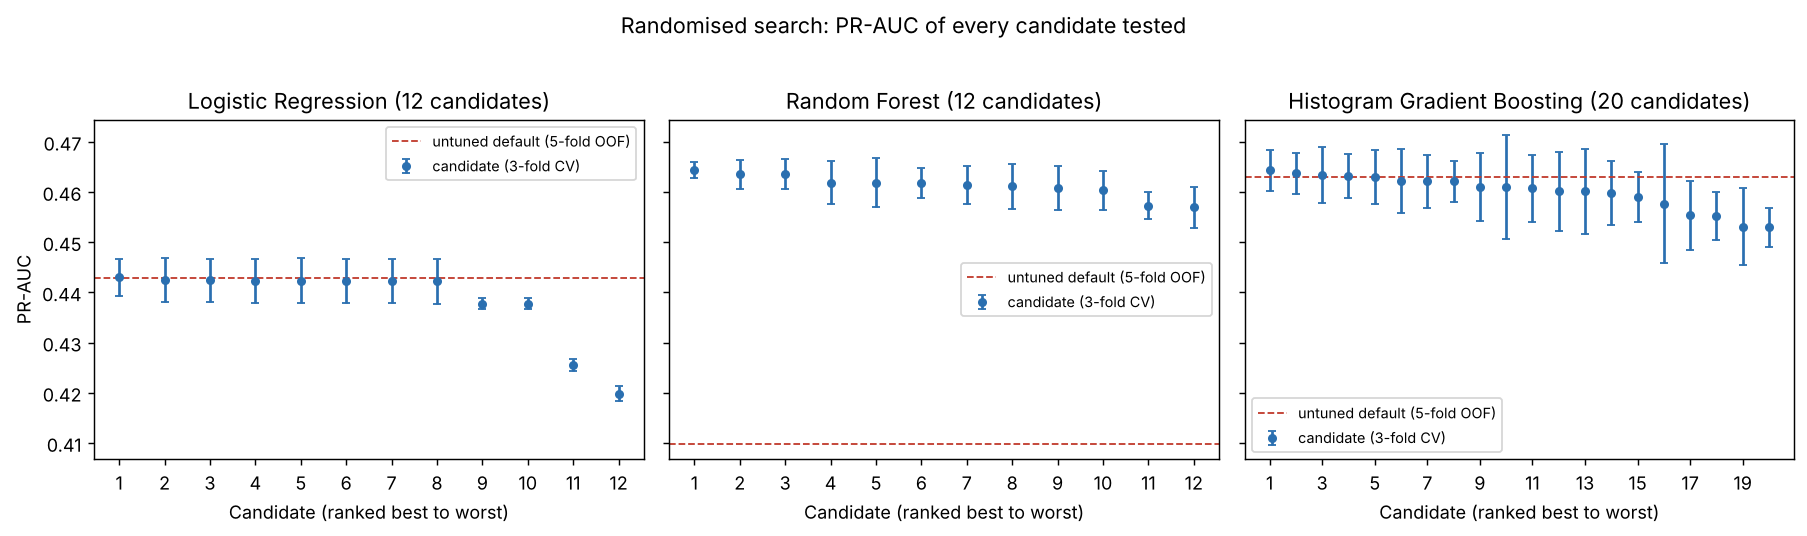

,default_pr_auc,tuned_pr_auc,default_roc_auc,tuned_roc_auc,default_mcc,tuned_mcc
model,,,,,,
Logistic Regression,0.4429,0.4434,0.7897,0.7899,0.4107,0.4110
Random Forest,0.4098,0.4628,0.7753,0.7987,0.3829,0.4319
Histogram Gradient Boosting,0.4629,0.4623,0.7996,0.7978,0.4311,0.4291


In [4]:
from src import tuning_analysis as ta
tuning_table = ta.main()
display(pd.read_csv(RESULTS_DIR / "tuning_trace_rf.csv").round(4))
display(Image(FIG_DIR / "14_tuning_search.png"))
tuning_table[["default_pr_auc", "tuned_pr_auc", "default_roc_auc", "tuned_roc_auc", "default_mcc", "tuned_mcc"]]

In [5]:
oof = oof_probas(tuned, X_tr, y_tr)
ranking = rank_models(oof, y_tr)
ranking[["roc_auc","pr_auc","f1","recall","precision","capture_top20"]]

oof logreg: 5s


oof rf: 7s


oof hgb: 2s


,roc_auc,pr_auc,f1,recall,precision,capture_top20
rf,0.7987,0.4628,0.5001,0.5715,0.4445,0.6333
hgb,0.7978,0.4623,0.4976,0.5675,0.4431,0.6357
logreg,0.7899,0.4434,0.4816,0.5344,0.4383,0.6252


## Part G: Ensemble learning
The two models with the highest out-of-fold PR-AUC are combined using:
* **soft voting**: the average of the two predicted probabilities
* **stacking**: a logistic regression "meta-learner" trained on the two models' out-of-fold probabilities

In [6]:
top2 = list(ranking.index[:2]); excluded = ranking.index[2]
print("Selected:", top2, "| excluded:", excluded)
print(pd.DataFrame(oof).corr(method="spearman").round(3))

Selected: ['rf', 'hgb'] | excluded: logreg
        logreg     rf    hgb
logreg   1.000  0.910  0.884
rf       0.910  1.000  0.929
hgb      0.884  0.929  1.000


In [7]:
from src import ensemble_selection as es
members_table, score_corr = es.main()
members_table

oof logreg: 4s


oof rf: 7s


oof hgb: 3s


,members,roc_auc,pr_auc,f1,mcc,capture_top20
RF + HGB,2.0,0.7996,0.4643,0.5010,0.4332,0.6370
RF,1.0,0.7987,0.4628,0.5001,0.4319,0.6333
HGB,1.0,0.7978,0.4623,0.4976,0.4291,0.6357
LR + RF + HGB,3.0,0.7982,0.4620,0.4980,0.4296,0.6354
LR + RF,2.0,0.7965,0.4585,0.4919,0.4225,0.6316
LR + HGB,2.0,0.7965,0.4574,0.4933,0.4242,0.6351
LR,1.0,0.7899,0.4434,0.4816,0.4110,0.6252


In [8]:
ens = build_ensembles(tuned, top2)
oof.update(oof_probas(ens, X_tr, y_tr))
oof_table = rank_models(oof, y_tr)
thresholds = {n: ev.best_f1_threshold(y_tr, p) for n, p in oof.items()}
oof_table[["roc_auc","pr_auc","f1","recall","precision","threshold"]]

oof voting: 12s


oof stacking: 57s


,roc_auc,pr_auc,f1,recall,precision,threshold
stacking,0.7997,0.4662,0.5009,0.5562,0.4556,0.7479
voting,0.7996,0.4643,0.5010,0.5589,0.4539,0.6748
rf,0.7987,0.4628,0.5001,0.5715,0.4445,0.6424
hgb,0.7978,0.4623,0.4976,0.5675,0.4431,0.6539
logreg,0.7899,0.4434,0.4816,0.5344,0.4383,0.6747


## Part H: Evaluation on the held-out test set
Every model is refitted on the full training set and scored ONCE on the untouched 20% test set,
using the thresholds chosen on training data.

In [9]:
all_est = {**tuned, **ens}
fitted, probas, test_default, test_tuned, cis = fit_and_test(all_est, X_tr, y_tr, X_te, y_te, thresholds)
test_tuned[["roc_auc","pr_auc","threshold","precision","recall","f1","balanced_acc","mcc","brier","capture_top20","fit_seconds"]]

,roc_auc,pr_auc,threshold,precision,recall,f1,balanced_acc,mcc,brier,capture_top20,fit_seconds
logreg,0.8002,0.4461,0.6747,0.4558,0.5506,0.4988,0.7336,0.4308,0.1628,0.6433,0.5515
rf,0.8112,0.4818,0.6424,0.4666,0.6024,0.5259,0.7575,0.4618,0.1462,0.6573,1.5192
hgb,0.8125,0.4862,0.6539,0.4640,0.6034,0.5246,0.7575,0.4604,0.1551,0.6627,0.4893
voting,0.8131,0.4869,0.6748,0.4795,0.5927,0.5301,0.7555,0.4667,0.1501,0.6606,2.0811
stacking,0.8129,0.4860,0.7479,0.4794,0.5894,0.5288,0.7541,0.4651,0.1595,0.6595,13.8756


In [10]:
test_default[["precision","recall","f1","mcc","tp","fp"]]

,precision,recall,f1,mcc,tp,fp
logreg,0.3530,0.6498,0.4575,0.3888,603.0,1105.0
rf,0.4051,0.6390,0.4958,0.4299,593.0,871.0
hgb,0.3794,0.6573,0.4811,0.4154,610.0,998.0
voting,0.3903,0.6476,0.4870,0.4210,601.0,939.0
stacking,0.3673,0.6638,0.4729,0.4072,616.0,1061.0


In [11]:
pd.DataFrame({k: {"ROC-AUC 95% CI": "%.3f to %.3f" % tuple(v["roc_auc_ci"]),
                  "PR-AUC 95% CI": "%.3f to %.3f" % tuple(v["pr_auc_ci"])} for k, v in cis.items()}).T

,ROC-AUC 95% CI,PR-AUC 95% CI
logreg,0.783 to 0.818,0.412 to 0.484
rf,0.795 to 0.828,0.447 to 0.517
hgb,0.796 to 0.830,0.452 to 0.521
voting,0.797 to 0.830,0.451 to 0.523
stacking,0.796 to 0.830,0.450 to 0.522


In [12]:
best_single = top2[0]
diffs = {}
for e in ("voting", "stacking"):
    for m, fn in (("pr_auc", ev.average_precision_score), ("roc_auc", ev.roc_auc_score)):
        r = ev.paired_bootstrap_diff(y_te.values, probas[e], probas[best_single], metric=fn)
        diffs[(e, m)] = {"mean diff vs " + best_single: r["mean_diff"], "95% CI low": r["ci"][0],
                         "95% CI high": r["ci"][1], "P(ensemble <= single)": r["p_le_zero"]}
pd.DataFrame(diffs).T.round(4)

mean diff vs rf  95% CI low  95% CI high  P(ensemble <= single)
voting   pr_auc            0.0050      0.0009       0.0093                  0.007
         roc_auc           0.0019     -0.0004       0.0042                  0.065
stacking pr_auc            0.0041      0.0014       0.0069                  0.001
         roc_auc           0.0016     -0.0000       0.0033                  0.026

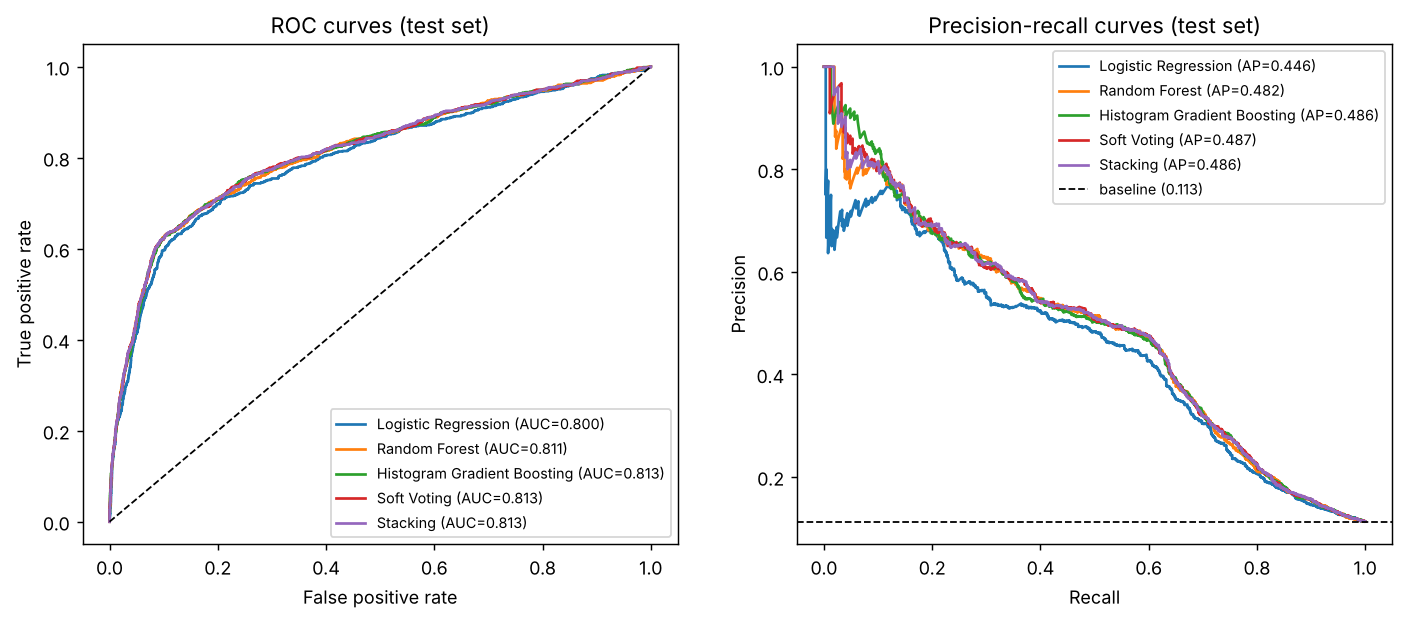

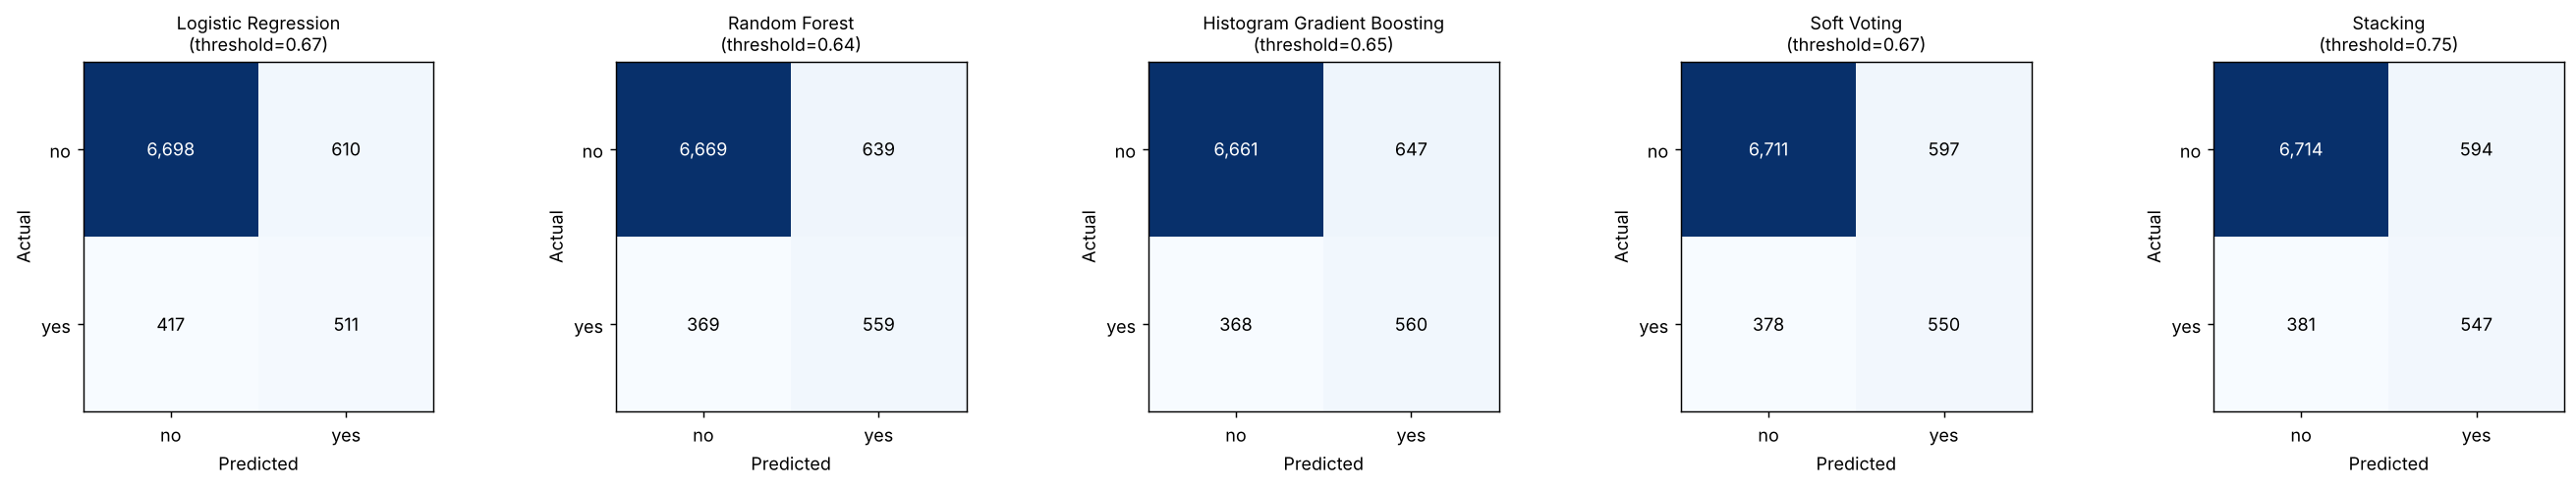

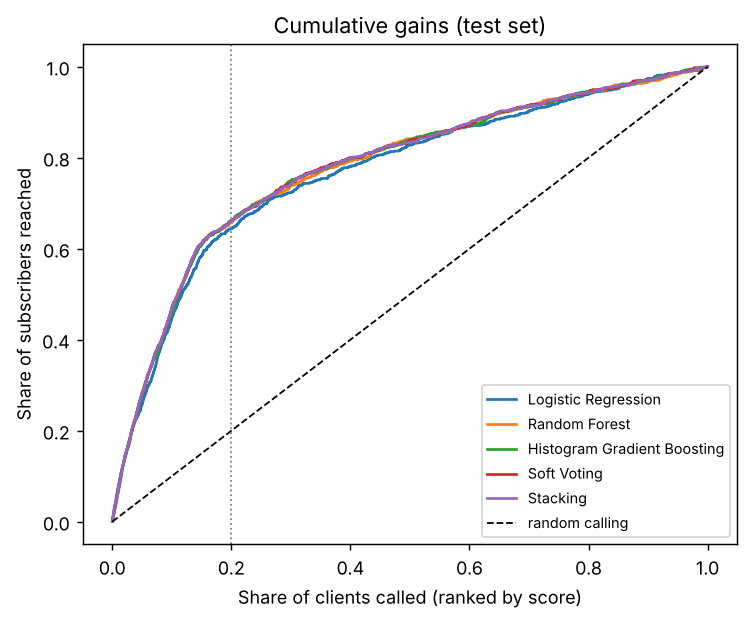

In [13]:
labels = {**MODEL_LABELS, "voting": "Soft Voting", "stacking": "Stacking"}
named = {labels[k]: v for k, v in probas.items()}
ev.plot_curves(y_te, named)
ev.plot_confusion_matrices(y_te, named, {labels[k]: v for k, v in thresholds.items()})
ev.plot_gain_chart(y_te, named)
for f in ["10_roc_pr_curves.png", "11_confusion_matrices.png", "12_cumulative_gains.png"]:
    display(Image(FIG_DIR / f))

### H4. What drives the predictions? (permutation importance)

In [14]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(fitted[best_single], X_te, y_te, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_te.columns).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=sns.color_palette("deep")[2])
ax.set(xlabel="Drop in test PR-AUC when shuffled", title=f"Permutation importance: {labels[best_single]}")
plt.show()
imp.sort_values("mean", ascending=False).head(10).round(4)

,mean,std
emp_var_rate,0.0390,0.0071
nr_employed,0.0329,0.0066
euribor3m,0.0313,0.0067
contact,0.0248,0.0037
poutcome,0.0198,0.0056
month,0.0102,0.0025
cons_price_idx,0.0091,0.0017
prev_contacted,0.0087,0.0024
day_of_week,0.0078,0.0019
cons_conf_idx,0.0069,0.0019


### H5. Business impact: calls needed per subscriber (soft-voting ensemble)

In [15]:
rows = []
for frac in (0.1, 0.2, 0.3, 0.5, 1.0):
    cap, lift = ev.lift_at(y_te.values, probas["voting"], frac)
    n_called = int(np.ceil(frac * len(y_te))); n_subs = int(round(cap * y_te.sum()))
    rows.append({"share called": frac, "clients called": n_called, "subscribers reached": n_subs,
                 "share of subscribers": round(cap, 3), "lift": round(lift, 2),
                 "calls per subscriber": round(n_called / n_subs, 2)})
biz = pd.DataFrame(rows).set_index("share called"); biz

,clients called,subscribers reached,share of subscribers,lift,calls per subscriber
share called,,,,,
0.1,824,438,0.472,4.72,1.88
0.2,1648,613,0.661,3.30,2.69
0.3,2471,690,0.744,2.48,3.58
0.5,4118,777,0.837,1.67,5.30
1.0,8236,928,1.000,1.00,8.88


### H6. Recommendation
We recommend deploying the **soft-voting ensemble of Random Forest and Gradient Boosting**. On the untouched test set it had the best PR-AUC (0.487), ROC-AUC, F1 and MCC, and the paired bootstrap shows its PR-AUC gain over Random Forest is small but real. Stacking scored about the same but trained roughly six times slower, so the simpler voting model is the better choice. The bank should use the ensemble's score to rank clients and call from the top down (the top 20% reaches about two-thirds of subscribers with about 70% fewer calls per deposit), keep Logistic Regression as an easy-to-explain companion, and retrain the model regularly because it leans heavily on economic indicators that drift over time.